# EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv('Nassau Candy Distributor.csv')
data.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [3]:
data.shape

(10194, 18)

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  int64  
 6   Country/Region  10194 non-null  object 
 7   City            10194 non-null  object 
 8   State/Province  10194 non-null  object 
 9   Postal Code     10194 non-null  object 
 10  Division        10194 non-null  object 
 11  Region          10194 non-null  object 
 12  Product ID      10194 non-null  object 
 13  Product Name    10194 non-null  object 
 14  Sales           10194 non-null  float64
 15  Units           10194 non-null  int64  
 16  Gross Profit    10194 non-null  float64
 17  Cost            10194 non-null 

In [5]:
data.describe()

,Row ID,Customer ID,Sales,Units,Gross Profit,Cost
count,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,134468.961154,13.908537,3.791838,9.166451,4.742087
std,2942.898656,20231.483007,11.341020,2.228317,6.643740,5.061647
min,1.000000,100006.000000,1.250000,1.000000,0.250000,0.600000
25%,2549.250000,117212.000000,7.200000,2.000000,4.900000,2.400000
50%,5097.500000,133550.000000,10.800000,3.000000,7.470000,3.600000
75%,7645.750000,152051.000000,18.000000,5.000000,12.250000,5.700000
max,10194.000000,192314.000000,260.000000,14.000000,130.000000,130.000000


# Data Cleaning and Validation

In [6]:
# check for duplicates

data[data.duplicated()]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost


In [7]:
# Need to change the dtype of the date columns

data['Order Date'] = pd.to_datetime(data['Order Date'], format = '%d-%m-%Y')

In [8]:
data['Ship Date'] = pd.to_datetime(data['Ship Date'], format = '%d-%m-%Y')

In [9]:
print('Order Date :', data['Order Date'].dtype)
print('Ship Date :', data['Ship Date'].dtype)

Order Date : datetime64[ns]
Ship Date : datetime64[ns]


In [10]:
# Remove invalid or negative lead times

In [11]:
temp_lead_time = (data['Ship Date'] - data['Order Date']).dt.days

negative_lead_time = (temp_lead_time < 0).sum()
print(f"⚠️ Records with Negative Lead Times: {negative_lead_time}")

⚠️ Records with Negative Lead Times: 0


#### There are no negative or invalid lead time present in the dataset.

In [12]:
# Handling missing shipment records

In [13]:
data.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Division          0
Region            0
Product ID        0
Product Name      0
Sales             0
Units             0
Gross Profit      0
Cost              0
dtype: int64

In [14]:
missing_order_date = data['Order Date'].isna().sum()

missing_ship_date = data['Ship Date'].isna().sum()

In [15]:
print(f"📅 Missing 'Order Date' records: {missing_order_date}")

print(f"🚚 Missing 'Ship Date' records: {missing_ship_date}")

📅 Missing 'Order Date' records: 0
🚚 Missing 'Ship Date' records: 0


#### Based on the above info and the summary, it's clearly visible that there are no missing values present in the shipment records and in the overall dataset.

In [16]:
# Standardize geographic fields

In [17]:
# Check for leading or trailing whitespaces

for col in ['Country/Region', 'City', 'State/Province', 'Region']:
    whitespace_mask = data[col].astype(str).str.contains(r'^\s|\s$', regex=True, na=False)
    whitespace_count = whitespace_mask.sum()
    print(f"🔍 '{col}' has {whitespace_count} rows with hidden spaces.")

🔍 'Country/Region' has 0 rows with hidden spaces.
🔍 'City' has 0 rows with hidden spaces.
🔍 'State/Province' has 0 rows with hidden spaces.
🔍 'Region' has 0 rows with hidden spaces.


#### There are no leading or trailing whitespaces present in the records.

In [18]:
for col in ['Country/Region', 'City', 'State/Province', 'Region']:
    # Find rows that are NOT properly Title Cased
    invalid_case_mask = ~data[col].astype(str).str.istitle() & data[col].notna()
    invalid_count = invalid_case_mask.sum()
    
    print(f"📌 '{col}' has {invalid_count} rows that are NOT in proper Title Case.")

📌 'Country/Region' has 0 rows that are NOT in proper Title Case.
📌 'City' has 6 rows that are NOT in proper Title Case.
📌 'State/Province' has 16 rows that are NOT in proper Title Case.
📌 'Region' has 0 rows that are NOT in proper Title Case.


There are total 6 records present in the City column that are in not proper title case and 16 records in State/Province column.

In [19]:
cols = ['City', 'State/Province']

for col in cols:
    if col in data.columns:
        not_title = ~data[col].astype(str).str.istitle()
        issue_count = not_title.sum()
        
        print(f"\n 📊 Column '{col}': Found {issue_count} rows with formatting issues.")
        
        if issue_count > 0:
            samples = data[not_title][col].unique()
            for sample in samples:
                print(f"  {sample}")
        else:
            print(f"⚠️ Column '{col}' not found in the DataFrame.")


 📊 Column 'City': Found 6 rows with formatting issues.
  St. John's

 📊 Column 'State/Province': Found 16 rows with formatting issues.
  Newfoundland and Labrador
  District of Columbia


#### After looking at those error values, there's nothing to worry about beacuse of the word 'and' & 'of ' present in the  "Newfoundland and Labrador" and  "District of Columbia" moreover that apostrophe in "St. John's", python istitle() method assumes that every word should start with a capital letter and after apostrophe, that's why it flagged those anomalies. We can ignore this and proceed further.

# Feature Engineering

In [20]:
# Calculate Shipping Lead Time (days)

data['Shipping_Lead_Time'] = (data['Ship Date'] - data['Order Date']).dt.days

data['Shipping_Lead_Time']

0         909
1         909
2         909
3         909
4         912
         ... 
10189    1639
10190    1639
10191    1639
10192    1639
10193    1639
Name: Shipping_Lead_Time, Length: 10194, dtype: int64

In [21]:
# Categorize routes by:
#    ○ Factory → Customer Region
#    ○ Factory → Customer State

In [22]:
# We'll create a mapping dictionary using product-to-factory

In [23]:
# First fix a specific typo: adding a missing space after the hyphen

data['Product Name'] = data['Product Name'].str.replace(
                                           'Wonka Bar -Scrumdiddlyumptious', 'Wonka Bar - Scrumdiddlyumptious', regex = False)

In [24]:
product_to_factory = {"Wonka Bar - Nutty Crunch Surprise" : "Lot's O' Nuts",
                      "Wonka Bar - Fudge Mallows" : "Lot's O' Nuts",
                      "Wonka Bar - Scrumdiddlyumptious" : "Lot's O' Nuts",
                      "Wonka Bar - Milk Chocolate" : "Wicked Choccy's",
                      "Wonka Bar - Triple Dazzle Caramel" : "Wicked Choccy's",
                      "Laffy Taffy" : "Sugar Shack",
                      "SweeTARTS" : "Sugar Shack",
                      "Nerds" : "Sugar Shack",
                      "Fun Dip" : "Sugar Shack",
                      "Fizzy Lifting Drinks" : "Sugar Shack",
                      "Everlasting Gobstopper" : "Secret Factory",
                      "Hair Toffee" : "The Other Factory",
                      "Lickable Wallpaper" : "Secret Factory",
                      "Wonka Gum" : "Secret Factory",
                      "Kazookles" : "The Other Factory"}

In [25]:
# Apply mapping to create the Factory origin column

data['Factory'] = data['Product Name'].map(product_to_factory)

In [26]:
# Fix a specific typo: adding a missing space after the hyphen

# data['Product Name'] = data['Product Name'].str.replace(
#                                            'Wonka Bar -Scrumdiddlyumptious', 'Wonka Bar - Scrumdiddlyumptious', regex = False)

In [27]:
data['Factory'].isnull().sum()

0

In [28]:
# Create distinct strings defining the unique origin-to-destination lanes

data['Route_Region'] = data['Factory'] + ' ➔ ' + data['Region']

data['Route_State/Province'] = data['Factory'] + ' ➔ ' + data['State/Province']

In [29]:
(data['Route_Region'] + '                 ' + data['Route_State/Province']).unique()

array(["Wicked Choccy's ➔ Interior                 Wicked Choccy's ➔ Texas",
       "Wicked Choccy's ➔ Interior                 Wicked Choccy's ➔ Illinois",
       "Lot's O' Nuts ➔ Interior                 Lot's O' Nuts ➔ Illinois",
       "Wicked Choccy's ➔ Atlantic                 Wicked Choccy's ➔ Pennsylvania",
       "Lot's O' Nuts ➔ Gulf                 Lot's O' Nuts ➔ Kentucky",
       "Wicked Choccy's ➔ Gulf                 Wicked Choccy's ➔ Kentucky",
       "Wicked Choccy's ➔ Gulf                 Wicked Choccy's ➔ Georgia",
       "Wicked Choccy's ➔ Pacific                 Wicked Choccy's ➔ California",
       "Wicked Choccy's ➔ Gulf                 Wicked Choccy's ➔ Virginia",
       'Secret Factory ➔ Gulf                 Secret Factory ➔ Virginia',
       "Wicked Choccy's ➔ Atlantic                 Wicked Choccy's ➔ Delaware",
       "Lot's O' Nuts ➔ Gulf                 Lot's O' Nuts ➔ South Carolina",
       "Lot's O' Nuts ➔ Atlantic                 Lot's O' Nuts ➔ Ohio",

In [30]:
#  Group shipments by Ship Mode

In [31]:
# Optimizing the column type to 'category' speeds up downstream groupby operations

data['Ship Mode'] = data['Ship Mode'].astype('category')

In [32]:
data['Ship Mode'].unique()

['Standard Class', 'First Class', 'Second Class', 'Same Day']
Categories (4, object): ['First Class', 'Same Day', 'Second Class', 'Standard Class']

# Route Definition & Aggregation

In [33]:
pd.set_option('display.expand_frame_repr', False)  # To stop Pandas from wrapping columns to a new line 


# 1. Micro-Route Aggregation (Factory ➔ Customer State)

state_route_summary = data.groupby('Route_State/Province').agg(
                      Total_Shipments = ('Shipping_Lead_Time', 'count'),
                      Avg_Lead_Time = ('Shipping_Lead_Time', 'mean'),
                      Lead_Time_Variability = ('Shipping_Lead_Time', 'std')     # 'std' calculates standard deviation
                      ).reset_index()

state_route_summary['Avg_Lead_Time'] = state_route_summary['Avg_Lead_Time'].round(2)
state_route_summary['Lead_Time_Variability'] = state_route_summary['Lead_Time_Variability'].round(2).fillna(0)
print(state_route_summary)

# 2. Macro-Route Aggregation (Factory ➔ Customer Region)

region_route_summary = data.groupby('Route_Region').agg(
                       Total_Shipments = ('Shipping_Lead_Time', 'count'),
                       Avg_Lead_Time = ('Shipping_Lead_Time', 'mean'), 
                       Lead_Time_Variability = ('Shipping_Lead_Time', 'std')
                       ).reset_index()

region_route_summary['Avg_Lead_Time'] = region_route_summary['Avg_Lead_Time'].round(2)
region_route_summary['Lead_Time_Variability'] = region_route_summary['Lead_Time_Variability'].round(2).fillna(0)
print('\n', region_route_summary)

print('\n✅ Aggregation Complete!')

                 Route_State/Province  Total_Shipments  Avg_Lead_Time  Lead_Time_Variability
0             Lot's O' Nuts ➔ Alabama               34        1295.21                 253.07
1             Lot's O' Nuts ➔ Alberta               16        1273.88                 266.92
2             Lot's O' Nuts ➔ Arizona              111        1306.20                 253.90
3            Lot's O' Nuts ➔ Arkansas               31        1285.35                 274.53
4    Lot's O' Nuts ➔ British Columbia               18        1273.78                 307.08
..                                ...              ...            ...                    ...
191         Wicked Choccy's ➔ Vermont                5        1418.60                 200.29
192        Wicked Choccy's ➔ Virginia              106        1238.88                 254.77
193      Wicked Choccy's ➔ Washington              221        1375.72                 270.80
194   Wicked Choccy's ➔ West Virginia                2        1639.00 

# Efficiency Benchmarking

In [34]:
# Rank routes from fastest to slowest and identify Top/Bottom 10

# We'll use our state_route_summary data

In [35]:
# Sort routes from fastest to slowest
rank_route = state_route_summary.sort_values(by = 'Avg_Lead_Time', ascending = True)

# Extract Top 10 most efficient (Shortest Lead Time)
top_10_routes =  rank_route.head(10)

# Extract Top 10 least efficient (Longest Lead Time)
bottom_10_routes = rank_route.tail(10)

In [36]:
top_10_routes

,Route_State/Province,Total_Shipments,Avg_Lead_Time,Lead_Time_Variability
76,Secret Factory ➔ Nebraska,1,906.0,0.00
80,Secret Factory ➔ New Mexico,2,906.0,2.83
121,The Other Factory ➔ Louisiana,1,907.0,0.00
115,The Other Factory ➔ Connecticut,2,907.5,2.12
158,Wicked Choccy's ➔ Maine,2,908.0,0.00
75,Secret Factory ➔ Mississippi,1,908.0,0.00
70,Secret Factory ➔ Louisiana,2,908.5,0.71
64,Secret Factory ➔ Delaware,1,909.0,0.00
88,Secret Factory ➔ South Carolina,1,909.0,0.00
74,Secret Factory ➔ Minnesota,1,909.0,0.00


In [37]:
bottom_10_routes

,Route_State/Province,Total_Shipments,Avg_Lead_Time,Lead_Time_Variability
69,Secret Factory ➔ Kentucky,2,1637.5,0.71
110,Sugar Shack ➔ Washington,1,1638.0,0.00
125,The Other Factory ➔ Nevada,1,1638.0,0.00
63,Secret Factory ➔ Connecticut,1,1638.0,0.00
97,Sugar Shack ➔ California,1,1638.0,0.00
37,Lot's O' Nuts ➔ North Dakota,5,1638.2,1.64
194,Wicked Choccy's ➔ West Virginia,2,1639.0,0.00
78,Secret Factory ➔ New Hampshire,1,1641.0,0.00
98,Sugar Shack ➔ Connecticut,1,1641.0,0.00
103,Sugar Shack ➔ New Jersey,1,1642.0,0.00


In [38]:
# Compare performance across ship modes

In [39]:
# We'll group the core dataframe by Ship Mode to see overall speed and consistency

ship_mode_summary = data.groupby('Ship Mode', observed = False).agg(
                    Total_Shipments = ('Shipping_Lead_Time', 'count'),
                    Avg_Lead_Time = ('Shipping_Lead_Time', 'mean'),
                    Lead_Time_Variability = ('Shipping_Lead_Time', 'std')
                    ).reset_index()

# Clean up formatting for presentation
ship_mode_summary['Avg_Lead_Time'] = ship_mode_summary['Avg_Lead_Time'].round(2)
ship_mode_summary['Lead_Time_Variability'] = ship_mode_summary['Lead_Time_Variability'].round(2).fillna(0)

print(ship_mode_summary)

        Ship Mode  Total_Shipments  Avg_Lead_Time  Lead_Time_Variability
0     First Class             1548        1338.28                 265.63
1        Same Day              547        1333.44                 253.81
2    Second Class             1979        1323.85                 261.81
3  Standard Class             6120        1314.33                 262.40


#### From the above table, we can conclude that, customers who are paying extra for "First Class" or "Same Day" shipping are actually waiting longer (by about 20 to 24 days on average) than customers who chose "Standard Class".

#### The variability (Lead_Time_Variability) is nearly identical across the board (~253 to 265 days). This means no matter what shipping mode the customer selects, their delivery window has a massive, unpredictable swing of almost 9 months.

# Geographic Bottleneck Analysis

In [40]:
# • Identify regions with:
#   -> High average lead time
#   -> High shipment volume + poor performance

In [41]:
# Sort regions purely by the longest average wait times

regional_bottlenecks = region_route_summary.sort_values(by = 'Avg_Lead_Time', ascending = False)

In [42]:
regional_bottlenecks

,Route_Region,Total_Shipments,Avg_Lead_Time,Lead_Time_Variability
11,Sugar Shack ➔ Pacific,3,1516.67,210.16
8,Sugar Shack ➔ Atlantic,18,1375.39,274.61
4,Secret Factory ➔ Atlantic,72,1349.25,280.72
5,Secret Factory ➔ Gulf,37,1332.54,304.83
19,Wicked Choccy's ➔ Pacific,1342,1329.10,266.22
0,Lot's O' Nuts ➔ Atlantic,1661,1326.83,255.99
18,Wicked Choccy's ➔ Interior,950,1324.55,266.33
2,Lot's O' Nuts ➔ Interior,1321,1324.20,258.41
10,Sugar Shack ➔ Interior,8,1318.62,235.26
3,Lot's O' Nuts ➔ Pacific,1813,1317.53,266.67


In [43]:
# Calculate the network-level averages across all regional routes

avg_regional_vol = region_route_summary['Total_Shipments'].mean()

avg_regional_lead_time = region_route_summary['Avg_Lead_Time'].mean()

In [44]:
# Filter for regions where BOTH volume and lead times are above average

high_vol_poor_perf_region = region_route_summary[
                                   (region_route_summary['Total_Shipments'] > avg_regional_vol) &
                                   (region_route_summary['Avg_Lead_Time'] > avg_regional_lead_time)
                                   ].sort_values(by = 'Avg_Lead_Time', ascending = False)

print("==== REGIONS WITH HIGH VOLUME + POOR PERFORMANCE ====")
print('\n', high_vol_poor_perf_region)

==== REGIONS WITH HIGH VOLUME + POOR PERFORMANCE ====

                   Route_Region  Total_Shipments  Avg_Lead_Time  Lead_Time_Variability
19   Wicked Choccy's ➔ Pacific             1342        1329.10                 266.22
0     Lot's O' Nuts ➔ Atlantic             1661        1326.83                 255.99
18  Wicked Choccy's ➔ Interior              950        1324.55                 266.33
2     Lot's O' Nuts ➔ Interior             1321        1324.20                 258.41
3      Lot's O' Nuts ➔ Pacific             1813        1317.53                 266.67
16  Wicked Choccy's ➔ Atlantic             1197        1315.97                 255.39
1         Lot's O' Nuts ➔ Gulf              897        1313.98                 266.59


#### Every single high-volume, poor-performing route belongs to only two factories: Wicked Choccy's and Lots' O' Nuts.  Other factories didn't make this list, meaning they are either lower volume or handling their delivery loads much better.

#### This tells us the root issue isn't a regional issue—the problem lies directly inside the operational or logistics processing of Wicked Choccy's and Lot's O' Nuts.

In [45]:
# Detect congestion-prone states or regions

In [46]:
# We define a bottleneck as a state with above-average volume AND above-average lead time.

avg_network_vol = state_route_summary['Total_Shipments'].mean()

avg_network_lead_time = state_route_summary['Avg_Lead_Time'].mean()

In [47]:
# Filter for states that break both thresholds

congested_states = state_route_summary[
                   (state_route_summary['Total_Shipments'] > avg_network_vol) &
                   (state_route_summary['Avg_Lead_Time'] > avg_network_lead_time)
                   ].sort_values(by = 'Avg_Lead_Time', ascending = False)

In [48]:
# Now we'll create a Combined Congestion Index

# To rank bottlenecks objectively, we multiply Volume by Lead Time to get a "Stress Score"

state_route_summary['Congestion Index'] = (state_route_summary['Total_Shipments'] * state_route_summary['Avg_Lead_Time'])

top_congestion_points = state_route_summary.sort_values(by = 'Congestion Index', ascending = False)

In [49]:
top_congestion_points

,Route_State/Province,Total_Shipments,Avg_Lead_Time,Lead_Time_Variability,Congestion Index
5,Lot's O' Nuts ➔ California,1125,1316.91,265.37,1481523.75
144,Wicked Choccy's ➔ California,823,1320.33,262.50,1086631.59
34,Lot's O' Nuts ➔ New York,645,1330.52,249.26,858185.40
49,Lot's O' Nuts ➔ Texas,569,1310.46,260.34,745651.74
173,Wicked Choccy's ➔ New York,436,1311.88,245.01,571979.68
...,...,...,...,...,...
74,Secret Factory ➔ Minnesota,1,909.00,0.00,909.00
64,Secret Factory ➔ Delaware,1,909.00,0.00,909.00
75,Secret Factory ➔ Mississippi,1,908.00,0.00,908.00
121,The Other Factory ➔ Louisiana,1,907.00,0.00,907.00


#### California is the absolute biggest operational bottleneck by a landslide. Both Lot's O' Nuts (1.48M score) and Wicked Choccy's (1.08M score) are completely chocked up when trying to fulfill orders to California, combining nearly 2000 shipments.

#### Behind California, New York and Texas are the next major problem areas, specifically driven by shipments originating from Lot's O' Nuts factory.

# Ship Mode Performance Analysis

In [50]:
# Compare shipping efficiency by:
# -> Standard shipping
# -> Expedited shipping

In [51]:
data['Ship Mode'].unique()

['Standard Class', 'First Class', 'Second Class', 'Same Day']
Categories (4, object): ['First Class', 'Same Day', 'Second Class', 'Standard Class']

In [52]:
# Broadly Categorize Shipping Tiers

ship_tier_mapping = {'Standard Class' : 'Standard Shipping',
                     'First Class' : 'Expedited Shipping',
                     'Same Day' : 'Expedited Shipping',
                     'Second Class' : 'Expedited Shipping'
                     }

In [53]:
data['Shipping_Tier'] =  data['Ship Mode'].map(ship_tier_mapping)

In [54]:
# Aggregrate performance metrics by tier

shipping_tier_summary = data.groupby('Shipping_Tier', observed = False).agg(
                        Total_Shipments = ('Shipping_Lead_Time', 'count'),
                        Avg_Lead_Time = ('Shipping_Lead_Time', 'mean'),
                        Lead_Time_Variability = ('Shipping_Lead_Time', 'std')
                        ).reset_index()

# Clean up decimal places
shipping_tier_summary['Avg_Lead_Time'] = shipping_tier_summary['Avg_Lead_Time'].round(2)
shipping_tier_summary['Lead_Time_Variability'] = shipping_tier_summary['Lead_Time_Variability'].round(2)

print(shipping_tier_summary)

        Shipping_Tier  Total_Shipments  Avg_Lead_Time  Lead_Time_Variability
0  Expedited Shipping             4074        1330.62                 262.24
1   Standard Shipping             6120        1314.33                 262.40


In [55]:
# Evaluate cost-time tradeoffs (descriptive)

### Cost-Time Tradeoff for Nassau Candy across three distinct core arguments:

### 1. The Inverted Cost-Time Paradigm

The fundamental trade-off in this dataset is completely broken. "Expedited Shipping" (which combines First Class, Same Day, and Second Class) takes an average of 1,330.62 days, while "Standard Shipping" takes 1,314.33 days.

The Insight: Customers are paying premium operational premiums for "fast" delivery, but they are systematically penalized with an additional 17 days of transit delay compared to the budget tier.

### 2. High Financial Risk & Low Predictability

Expedited shipping tiers usually charge a premium because they secure guaranteed space on trucks or flights, which lowers delivery volatility.

The Insight: The Lead_Time_Variability is virtually identical between Standard (262.40) and Expedited (262.24). Nassau Candy cannot market its premium tiers as "reliable" because selecting an expedited option provides zero protection against massive multi-month transit swings.

### 3. Business Recommendations for the Capstone Report

To conclude the analysis framework, there are two high-impact executive recommendations based on this phase:

Immediate Financial Audit: Nassau Candy should immediately audit or suspend their expedited carrier contracts. They are paying premium line-haul rates to logistics partners who are delivering worse timelines than standard postal/ground options.

Customer Retention Strategy: Because premium tiers underperform, billing customers extra for "First Class" or "Same Day" delivery poses a massive legal and customer retention risk. The company should offer standard pricing margins across the board until the core fulfillment system is repaired.

# Data Visualization

In [56]:
# Set clean, professional styling for the charts

sns.set_style(style = "whitegrid")

In [57]:
# The Inverted Shipping Tier Reality (Methodology 4 & 6)

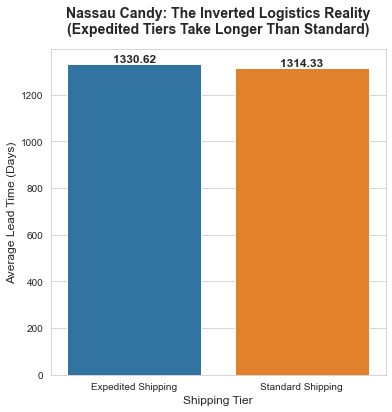

In [58]:
# Create a bar plot comparing Standard vs. Expedited lead times

plt.figure(figsize = (6,6))
ax1 = sns.barplot(x = 'Shipping_Tier', y = 'Avg_Lead_Time', estimator = sum , ci = None, data = shipping_tier_summary)
ax1.bar_label(ax1.containers[0], fontsize = 12, weight = 'bold')
plt.title("Nassau Candy: The Inverted Logistics Reality\n(Expedited Tiers Take Longer Than Standard)", fontsize = 14, pad = 15, weight = 'bold')
plt.xlabel("Shipping Tier", fontsize = 12)
plt.ylabel("Average Lead Time (Days)", fontsize = 12)
plt.show()

In [59]:
# Top 5 State Congestion Points (Methodology 5)

In [60]:
top_5_congested = state_route_summary.sort_values(by = 'Congestion Index', ascending = False).head(5).copy()

In [61]:
top_5_congested['Congestion_Index_Millions'] = top_5_congested['Congestion Index'] / 1000000

In [62]:
# Tells Matplotlib to search for the character in Segoe UI Emoji or Arial if the default fails
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Segoe UI Emoji", "Arial"]

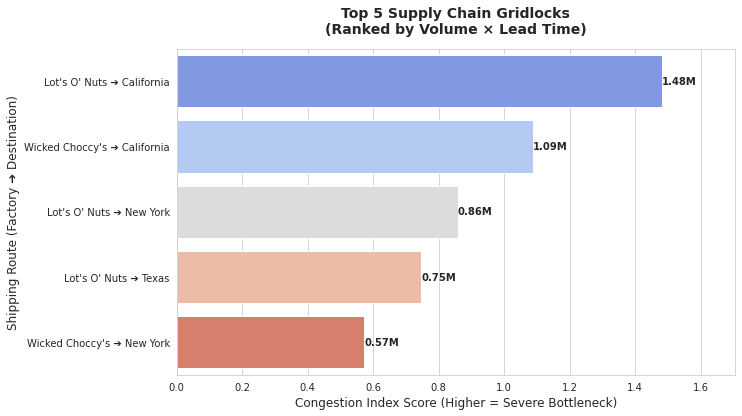

In [63]:
plt.figure(figsize = (10, 6))

ax2 = sns.barplot(x = 'Congestion_Index_Millions', y = 'Route_State/Province', estimator = sum, ci = None, data = top_5_congested, palette = 'coolwarm')

ax2.bar_label(ax2.containers[0], fmt='%.2fM', fontsize = 10, weight = 'bold')

plt.title("Top 5 Supply Chain Gridlocks\n(Ranked by Volume × Lead Time)", fontsize = 14, pad = 15, weight = 'bold')
plt.xlabel("Congestion Index Score (Higher = Severe Bottleneck)", fontsize = 12)
plt.ylabel("Shipping Route (Factory ➔ Destination)", fontsize = 12)

# Give the right side some breathing room for the labels
ax2.set_xlim(0, top_5_congested['Congestion_Index_Millions'].max() * 1.15)

plt.show()

In [64]:
# Delay Frequency (% of shipments exceeding a threshold)

In [65]:
# Let's assume a shipment is "delayed" if it exceeds the network median lead time

threshold_days = data['Shipping_Lead_Time'].median()

In [66]:
# Calculate the percentage of delayed shipments per route

delay_stats = data.groupby('Route_State/Province').agg(
              Delay_Frequency = ('Shipping_Lead_Time', lambda x: (x > threshold_days).mean() * 100)
              ).reset_index()

In [67]:
state_route_summary = state_route_summary.merge(delay_stats, on = 'Route_State/Province')

In [68]:
# Route Efficiency Score (Normalized performance from 0 to 100)

In [69]:
# Lower lead times should mean HIGHER efficiency. 
# We invert the normalized scale so the fastest route gets a 100 and the slowest gets a 0.

min_lead = state_route_summary['Avg_Lead_Time'].min()

max_lead = state_route_summary['Avg_Lead_Time'].max()

In [70]:
state_route_summary['Route_Efficiency_Score'] = ((max_lead - state_route_summary['Avg_Lead_Time']) / 
                                                (max_lead - min_lead) * 100).round(2)

In [71]:
state_route_summary['Delay_Frequency'] = state_route_summary['Delay_Frequency'].round(2)

In [72]:
state_route_summary.sort_values(by = 'Route_Efficiency_Score', ascending = False).head()

,Route_State/Province,Total_Shipments,Avg_Lead_Time,Lead_Time_Variability,Congestion Index,Delay_Frequency,Route_Efficiency_Score
80,Secret Factory ➔ New Mexico,2,906.0,2.83,1812.0,0.0,100.00
76,Secret Factory ➔ Nebraska,1,906.0,0.00,906.0,0.0,100.00
121,The Other Factory ➔ Louisiana,1,907.0,0.00,907.0,0.0,99.86
115,The Other Factory ➔ Connecticut,2,907.5,2.12,1815.0,0.0,99.80
75,Secret Factory ➔ Mississippi,1,908.0,0.00,908.0,0.0,99.73


In [73]:
state_route_summary.sort_values(by = 'Route_Efficiency_Score', ascending = True).head()

,Route_State/Province,Total_Shipments,Avg_Lead_Time,Lead_Time_Variability,Congestion Index,Delay_Frequency,Route_Efficiency_Score
103,Sugar Shack ➔ New Jersey,1,1642.0,0.00,1642.0,100.0,0.00
78,Secret Factory ➔ New Hampshire,1,1641.0,0.00,1641.0,100.0,0.14
98,Sugar Shack ➔ Connecticut,1,1641.0,0.00,1641.0,100.0,0.14
194,Wicked Choccy's ➔ West Virginia,2,1639.0,0.00,3278.0,100.0,0.41
37,Lot's O' Nuts ➔ North Dakota,5,1638.2,1.64,8191.0,100.0,0.52


In [74]:
import pickle

In [77]:
# data.to_pickle(r"D:\Unified Mentor Projects\clean_shipments.pkl")

In [78]:
# state_route_summary.to_pickle(r"D:\Unified Mentor Projects\state_summary.pkl")

In [81]:
# Set publication-ready academic style (clean white background, sharp typography)

In [85]:
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['figure.titlesize'] = 14
plt.style.use('seaborn-whitegrid')

In [87]:
df = pd.read_pickle("clean_shipments.pkl")

In [86]:
# FIGURE 1: Tri-Modal Fulfillment Latency Distribution (Histogram + KDE)

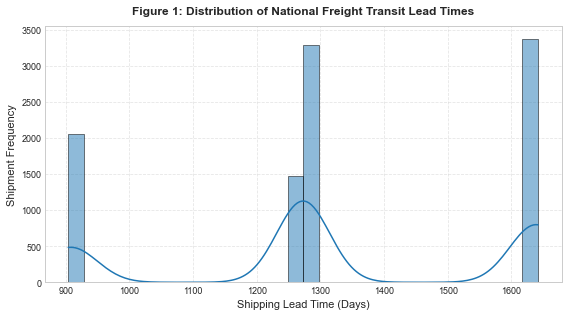

In [92]:
plt.figure(figsize=(8, 4.5))
ax = sns.histplot(x = 'Shipping_Lead_Time', 
                  data = df, 
                  kde = True, 
                  color = '#1f77b4',        # Standard academic slate blue
                  edgecolor = 'black', 
                  linewidth = 0.5, 
                  bins = 30)


# Annotate peaks/clusters for paper reference
plt.title('Figure 1: Distribution of National Freight Transit Lead Times', pad = 12, fontweight = 'bold')
plt.xlabel('Shipping Lead Time (Days)')
plt.ylabel('Shipment Frequency')
plt.grid(True, linestyle = '--', alpha = 0.5)


# Save high-resolution PNG for academic paper embedding
plt.tight_layout()
plt.savefig('Figure1_LeadTime_Distribution.png', dpi = 300, bbox_inches = 'tight')
plt.show()

In [93]:
# FIGURE 2: Route Efficiency Score (Er) by Customer State (Horizontal Bar Chart)

In [107]:
state_summary = pd.read_pickle('state_summary.pkl')

In [121]:
# 1. Calculate state-level metrics
state_summary = df.groupby('State/Province').agg(
                Avg_Lead_Time = ('Shipping_Lead_Time', 'mean')
                ).reset_index()

min_lead = state_summary['Avg_Lead_Time'].min()
max_lead = state_summary['Avg_Lead_Time'].max()


# 2. Compute Efficiency Score (Er)
if max_lead != min_lead:
    state_summary['Route_Efficiency_Score'] = ((max_lead - state_summary['Avg_Lead_Time']) / 
                                               (max_lead - min_lead) * 100)
else:
    state_summary['Route_Efficiency_Score'] = 100.0

    
# 3. Extract Bottom 10 (Bottlenecks) and Top 10 (High Efficiency)
state_summary = state_summary.sort_values(by = 'Route_Efficiency_Score', ascending = True)
top_10 = state_summary.head(10)
bottom_10 = state_summary.tail(10)


# Combine into a clean 20-row dataframe
plot_df = pd.concat([bottom_10, top_10]).drop_duplicates().sort_values(by = 'Route_Efficiency_Score', ascending = True)

In [ ]:
## To display all the states

# plt.figure(figsize = (8, 16))

# # Use color gradient: lower scores get darker red/orange, high scores get slate blue
# colors = ['#d95f02' if score < 40 else '#1f77b4' for score in state_summary['Route_Efficiency_Score']]


# bars = plt.barh(state_summary['State/Province'],
#                 state_summary['Route_Efficiency_Score'],
#                 color = colors,
#                 edgecolor = 'black',
#                 linewidth = 0.5,
#                 height = 0.6)


# # Add score labels on top of bars
# for bar in bars:
#     width = bar.get_width()
#     plt.text(width + 1.5,
#              bar.get_y() + bar.get_height() / 2,
#              f'{width:.1f}',
#              va = 'center',
#              ha = 'left',
#              fontsize = 8.5)
    

# plt.title('Figure 2: Normalized Route Efficiency Score ($E_r$) by Destination State', pad = 12, fontweight = 'bold')
# plt.xlabel('Route Efficiency Score ($E_r$) [0 = Lowest Efficiency, 100 = Highest Efficiency]')
# plt.ylabel('Customer State/Province')
# plt.xlim(0, 115)  # Leave room for labels
# plt.grid(True, linestyle = '--', alpha = 0.5, axis = 'x')


# plt.tight_layout()
# plt.savefig('Figure2_State_Efficiency_Ranking.png', dpi = 300, bbox_inches = 'tight')
# plt.show()








# plt.figure(figsize = (8, 16))  # Increase vertical height from 6 to 16

# bars = plt.barh(state_summary['Customer State'],
#                 state_summary['Route_Efficiency_Score'],
#                 color = colors,
#                 edgecolor = 'black',
#                 linewidth = 0.4,
#                 height = 0.5
#                 )

# # Shrink y-tick font size so names don't overlap
# plt.yticks(fontsize = 7)
# plt.xticks(fontsize = 8)

# for bar in bars:
#     width = bar.get_width()
#     plt.text(width + 1.0, bar.get_y() + bar.get_height()/2, f'{width:.1f}', va = 'center', ha = 'left', fontsize = 6.5)

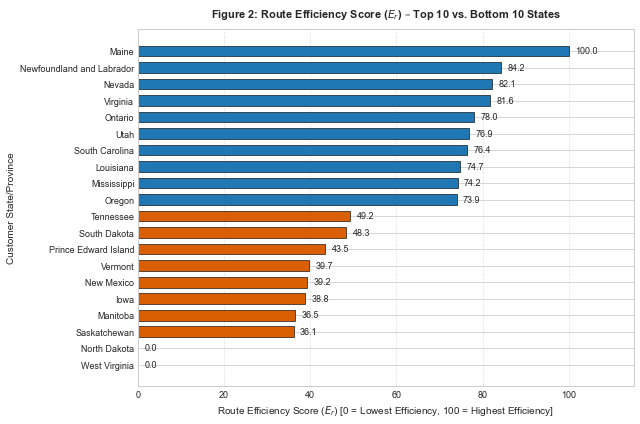

In [126]:
plt.figure(figsize = (9, 6))

# Use color gradient: lower scores get darker red/orange, high scores get slate blue
colors = ['#d95f02' if score < 50 else '#1f77b4' for score in plot_df['Route_Efficiency_Score']]


bars = plt.barh(plot_df['State/Province'],
                plot_df['Route_Efficiency_Score'],
                color = colors,
                edgecolor = 'black',
                linewidth = 0.6,
                height = 0.65)


# Add score labels on top of bars
for bar in bars:
    width = bar.get_width()
    plt.text(width + 1.5,
             bar.get_y() + bar.get_height() / 2,
             f'{width:.1f}',
             va = 'center',
             ha = 'left',
             fontsize = 9)
    

plt.title('Figure 2: Route Efficiency Score ($E_r$) – Top 10 vs. Bottom 10 States', pad = 12, fontweight = 'bold', fontsize = 11)
plt.xlabel('Route Efficiency Score ($E_r$) [0 = Lowest Efficiency, 100 = Highest Efficiency]', fontsize = 10)
plt.ylabel('Customer State/Province', fontsize = 10)
plt.xlim(0, 115)
plt.grid(True, linestyle = '--', alpha = 0.5, axis = 'x')


plt.tight_layout()
plt.savefig('Figure2_State_Efficiency_Top_Bottom.png', dpi = 300, bbox_inches = 'tight')
plt.show()

In [125]:
# FIGURE 3: Fulfillment Duration & Dispersion Across Ship Modes (Box Plot)

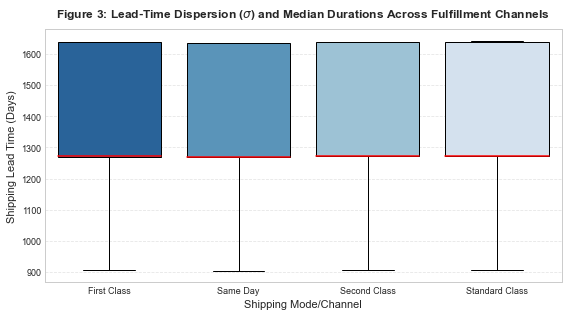

In [128]:
plt.figure(figsize=(8, 4.5))

sns.boxplot(x = 'Ship Mode',
            y = 'Shipping_Lead_Time',
            data = df,
            palette = 'Blues_r',
            boxprops = dict(edgecolor = 'black', linewidth = 1),
            whiskerprops = dict(color = 'black', linewidth = 1),
            capprops = dict(color = 'black', linewidth = 1),
            medianprops = dict(color = 'red', linewidth = 1.5)
            )


plt.title('Figure 3: Lead-Time Dispersion ($\sigma$) and Median Durations Across Fulfillment Channels', pad = 12, fontweight = 'bold')
plt.xlabel('Shipping Mode/Channel')
plt.ylabel('Shipping Lead Time (Days)')
plt.grid(True, linestyle = '--', alpha = 0.5, axis = 'y')


plt.tight_layout()
plt.savefig('Figure3_ShipMode_Dispersion.png', dpi = 300, bbox_inches = 'tight')
plt.show()